# GH-II model

After trying `test-0-x`, now, we proceed to propose canonical toy models for the paper and test basic properties, preparing for scanning.

`test-2-x` are for the GH-II model, which is more like `GLU`.

In this model, the input $x\in \mathbb{R}^m$. We have a key matrix $K \in \mathbb{R}^{d\times m}$, a gate matrix $G \in \mathbb{R}^{d \times m}$, and a value tensor $V \in \mathbb{R}^{m \times d}$. The output of the gate is computed as:
$$
h =  V(Gx \odot Kx).
$$
We call this part G-II, gate model type II.
After the gate, we project the hidden state out with a head $W \in \mathbb{R}^{n\times m}$, and the final logits is:
$$
y = Wh \in \mathbb{R}^n.
$$

Visually, one can see
<img src="GHmodels.jpeg" alt="GHmodels" width="600">

We want the toy model to have the following properties:
- 1/3 scaling for gate part
- 3/4 situations of GH can show the 1/3 scaling, 1/4 situation means both high temperature.
- Maybe increasing Hessian, not necessary.

## G-II model

`test-2` is for testing G-II.

In [56]:
import torch
import torch.nn.functional as F
import torch.nn as nn
from dataclasses import dataclass
import matplotlib.pyplot as plt

In [ ]:
# ---- Config ----
@dataclass
class Config:
    vocab_size: int = 128     # vocab size (n)
    n_embd: int = 32         # model width (m)
    beta: float = 1.0              # scaling factor for the logits
    beta_g: float = 1.0            # scaling factor for the gating
    teacher: bool = False             # whether to use teacher model
    d_h: int = 96             # hidden dimension in gate

# ---- Utils ----
def rmsnorm(x: torch.Tensor):
    return F.rms_norm(x, (x.size(-1),))

# ---- Model ----
class GATE_II(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        if cfg.teacher:
            self.K = torch.nn.Parameter(torch.randn(cfg.d_h, cfg.n_embd)/ (cfg.n_embd ** 0.5))
            self.G = torch.nn.Parameter(torch.randn(cfg.d_h, cfg.n_embd) * cfg.beta_g / (cfg.n_embd ** 0.5))
            self.V = torch.nn.Parameter(torch.randn(cfg.n_embd, cfg.d_h) / (cfg.d_h ** 0.5))
        else:
            self.K = torch.nn.Parameter(torch.randn(cfg.d_h, cfg.n_embd)/ (cfg.n_embd ** 0.5))
            self.G = torch.nn.Parameter(torch.zeros(cfg.d_h, cfg.n_embd))
            self.V = torch.nn.Parameter(torch.zeros(cfg.n_embd, cfg.d_h))

    def forward(self, x: torch.Tensor):
        # x: (batch_size, n_embd)
        keys = F.linear(x, self.K)  # (batch_size, d_h)
        gates = F.sigmoid(F.linear(x, self.G))  # (batch_size, d_h)
        keys = keys * gates  # (batch_size, d_h)
        out = F.linear(keys, self.V)  # (batch_size, n_embd)
        return out

In [83]:
t_cfg = Config(beta = 1.0, beta_g = 500.0, teacher = True)
teacher = GATE_II(t_cfg)
s_cfg = Config()
student = GATE_II(s_cfg)
with torch.no_grad():
    student.K.copy_(teacher.K + torch.randn_like(teacher.K) * 0.1)
    student.V.copy_(teacher.V + torch.randn_like(teacher.V) * 0.1)

init_K = student.K.detach().clone()
init_V = student.V.detach().clone()
batch_size = 2048
base_lr = 3e-2

optimizer = torch.optim.AdamW([{'params': [student.K, student.V], 'lr': base_lr},
                               {'params': [student.G], 'lr': base_lr}])

losses = []
#s_logits_stds = []
#t_logits_stds = []
#entropies = []
#t_entropies = []
s_beta_G = []
K_diff = []
V_diff = []

num_steps = 2000 # 18s
for step in range(num_steps):
    x = torch.randn(batch_size, s_cfg.n_embd)
    with torch.no_grad():
        teacher_logits = teacher(x)
    student_logits = student(x)
    #loss = F.kl_div(student_log_probs, teacher_log_probs, reduction='batchmean', log_target=True)
    loss = F.mse_loss(student_logits, teacher_logits)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    s_beta_G.append(student.G.norm().item() / (s_cfg.d_h ** 0.5))
    K_diff.append((student.K - init_K).norm().item())
    V_diff.append((student.V - init_V).norm().item())

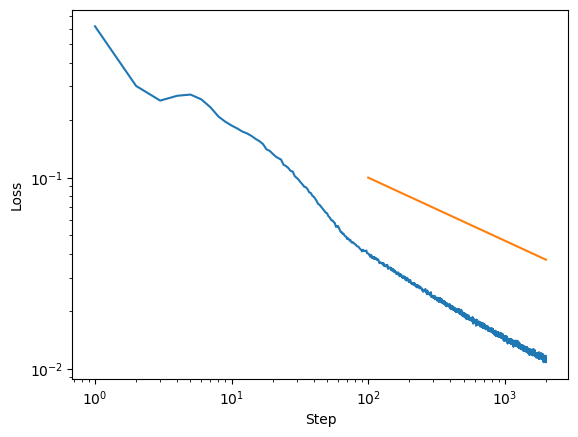

In [84]:
plt.plot(range(1, len(losses) + 1), losses)
plt.plot([100, 2000], [.1, .1/20**0.33])
plt.xlabel('Step')
plt.ylabel('Loss')
plt.xscale('log')
plt.yscale('log')

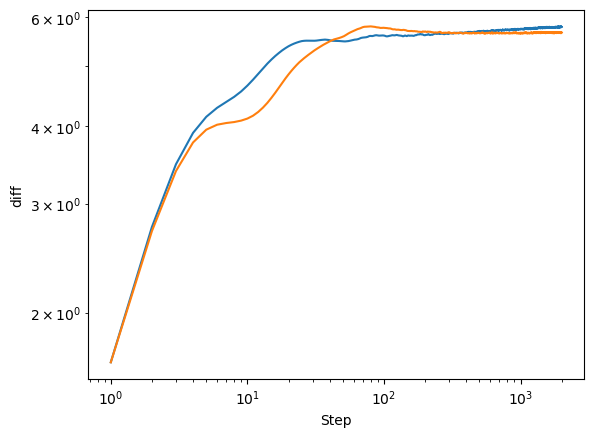

In [85]:
plt.plot(range(1, len(losses) + 1), K_diff)
plt.plot(range(1, len(losses) + 1), V_diff)
plt.xlabel('Step')
plt.ylabel('diff')
plt.xscale('log')
plt.yscale('log')

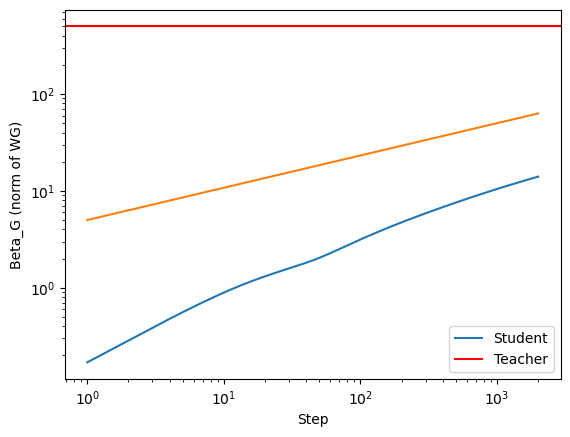

In [86]:
plt.plot(range(1, len(losses) + 1), s_beta_G, label='Student')
plt.axhline(t_cfg.beta_g, label='Teacher', color='red')
plt.plot([1,2000], [5, 5 * 2000 ** (1/3)])
plt.xlabel('Step')
plt.ylabel('Beta_G (norm of WG)')
plt.xscale('log')
plt.yscale('log')
plt.legend()